In [ ]:
import numpy as np
import marimo as mo
import seaborn as sns
import scipy as scp
import pandas as pd
import matplotlib.pyplot as plt
import altair as alt
from mpl_toolkits.mplot3d import Axes3D

In [ ]:
scores_dataframe = pd.read_csv("/media/adityamoger/T7/run_simulation_for_optima/summary_merged_26_10_2026.csv")
# scores_dataframe = scores_dataframe[scores_dataframe["duration"]*0.001*scores_dataframe["BAT_FAST_SPEED"]>70]

In [ ]:
# diagnostics
plt.hist(scores_dataframe["SPL_THRESHOLD_FOR_ATTRACTION"])

# Sensitivity analysis; Figure S1
## Goal
1. To indentify parameters that are ideal for testing the model in different situations and,
2. To find the parameters that most influece model outcome!

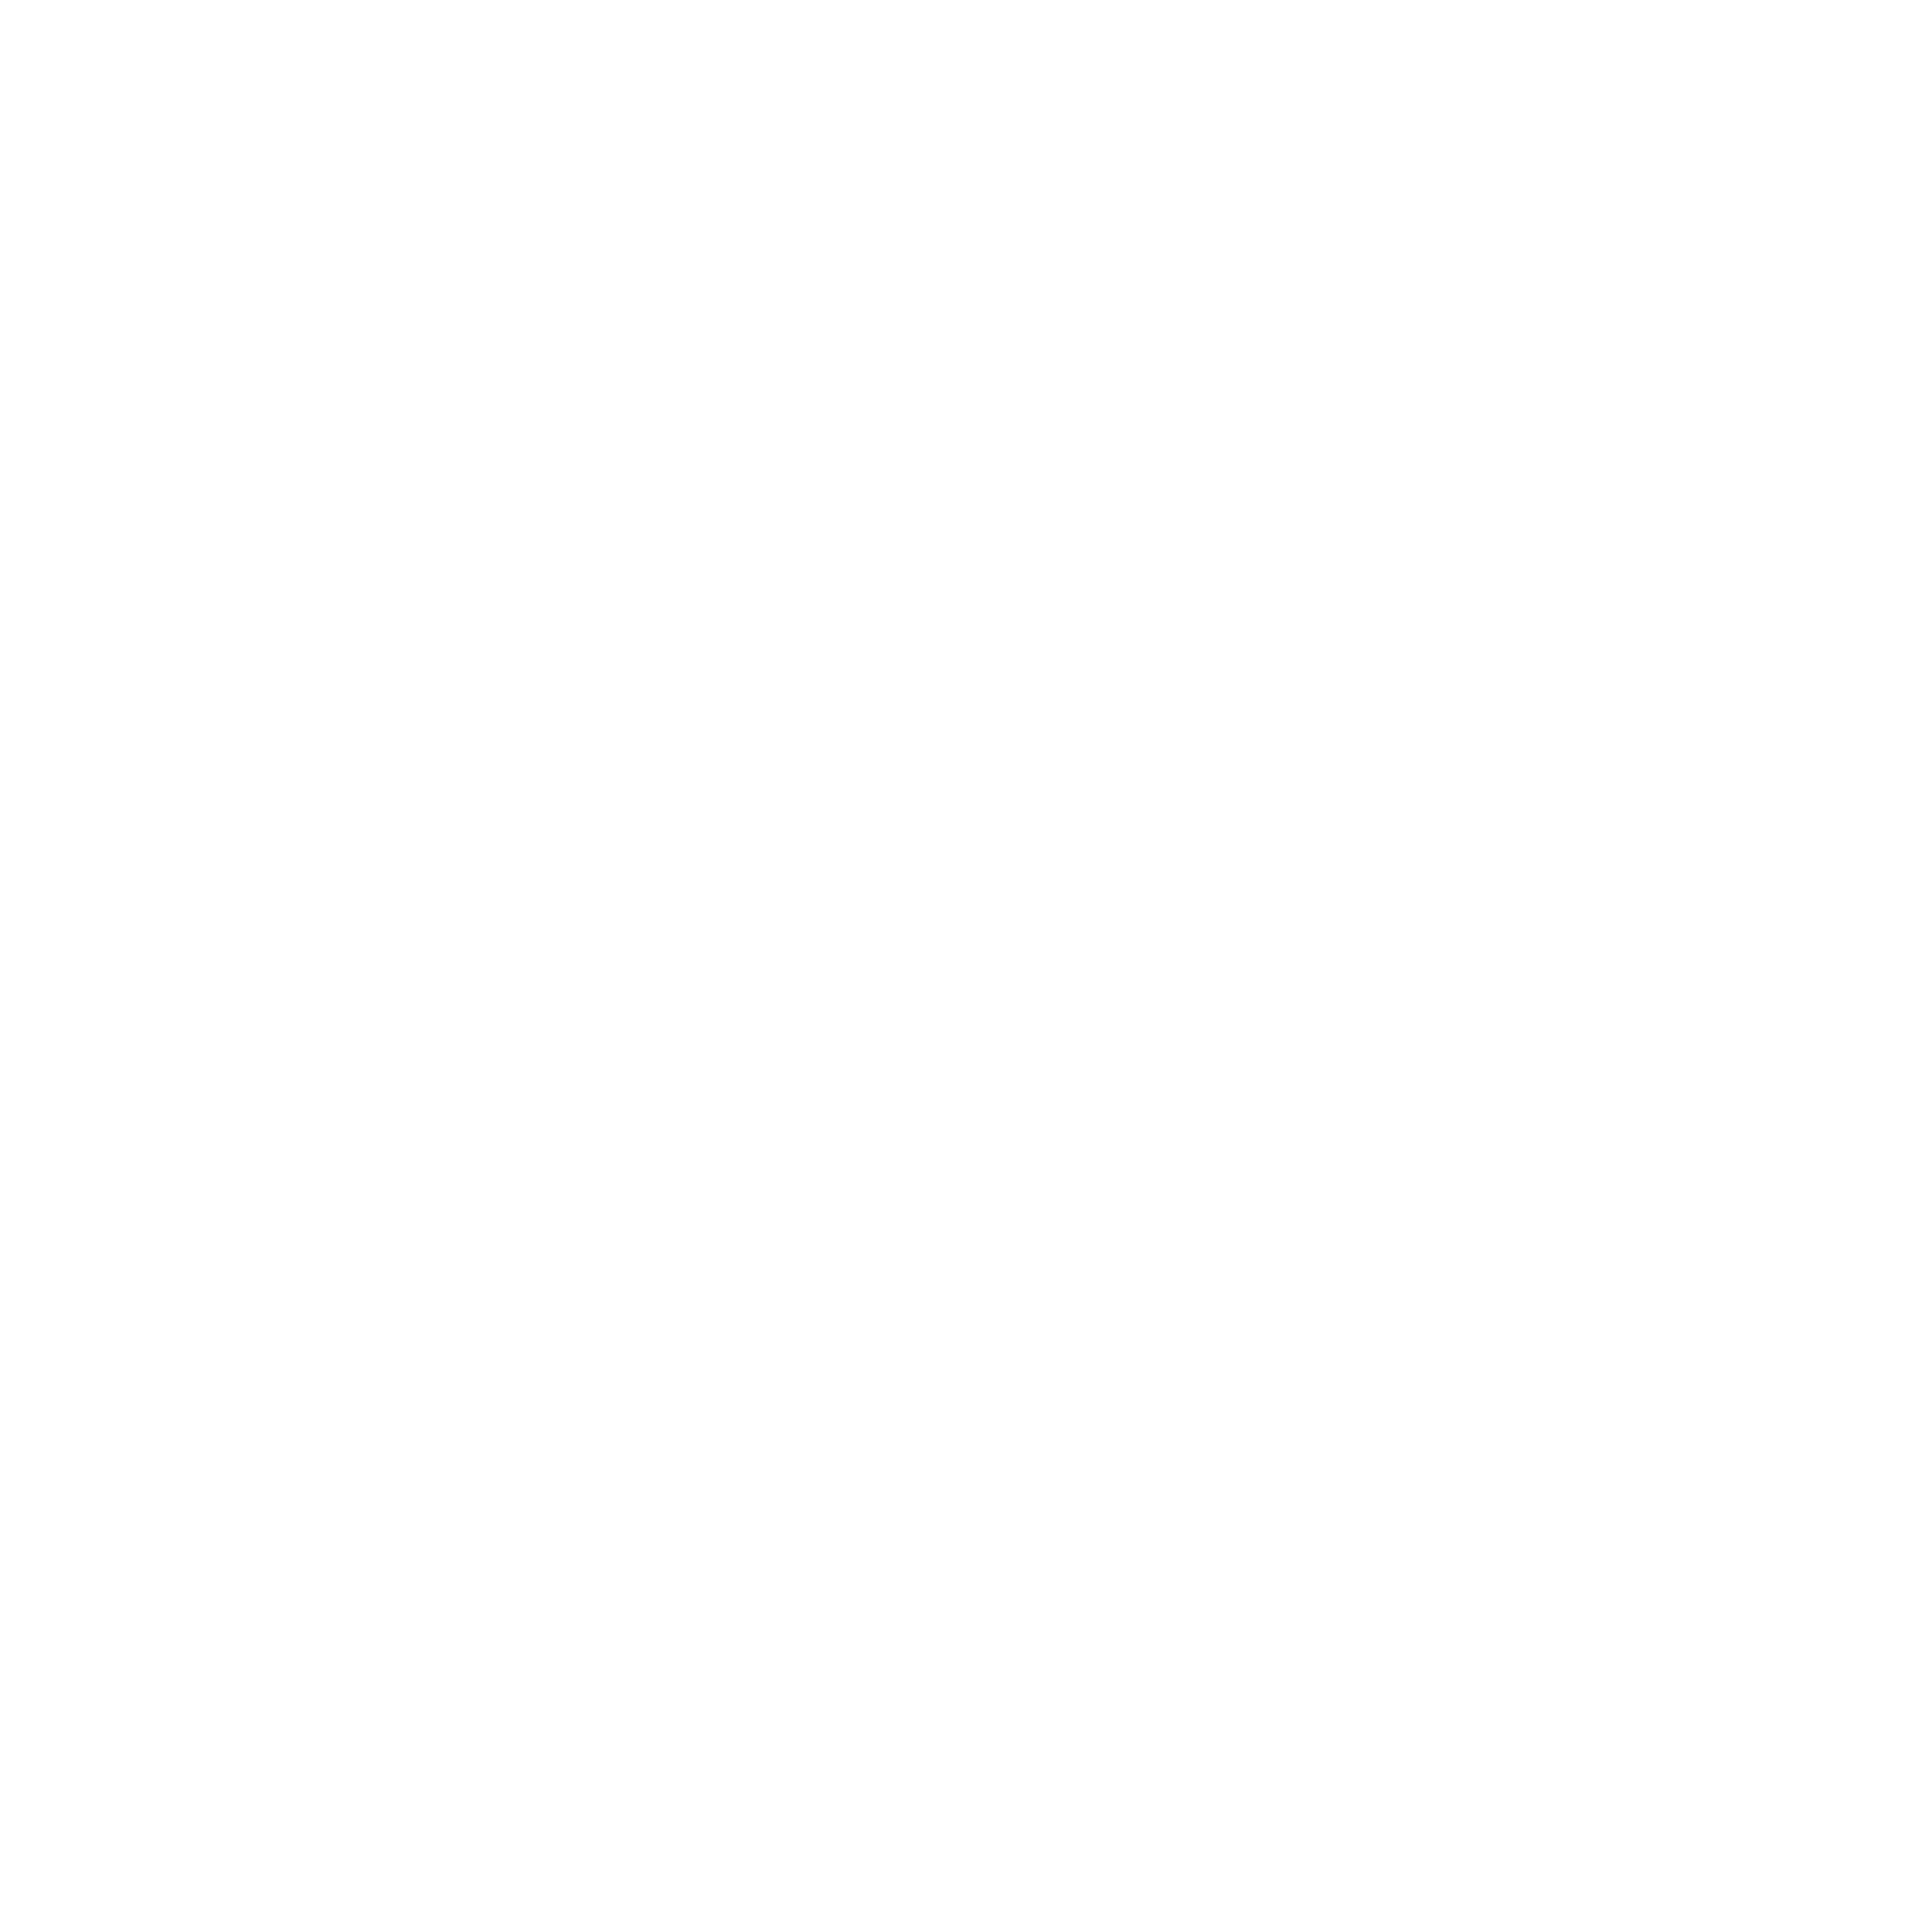

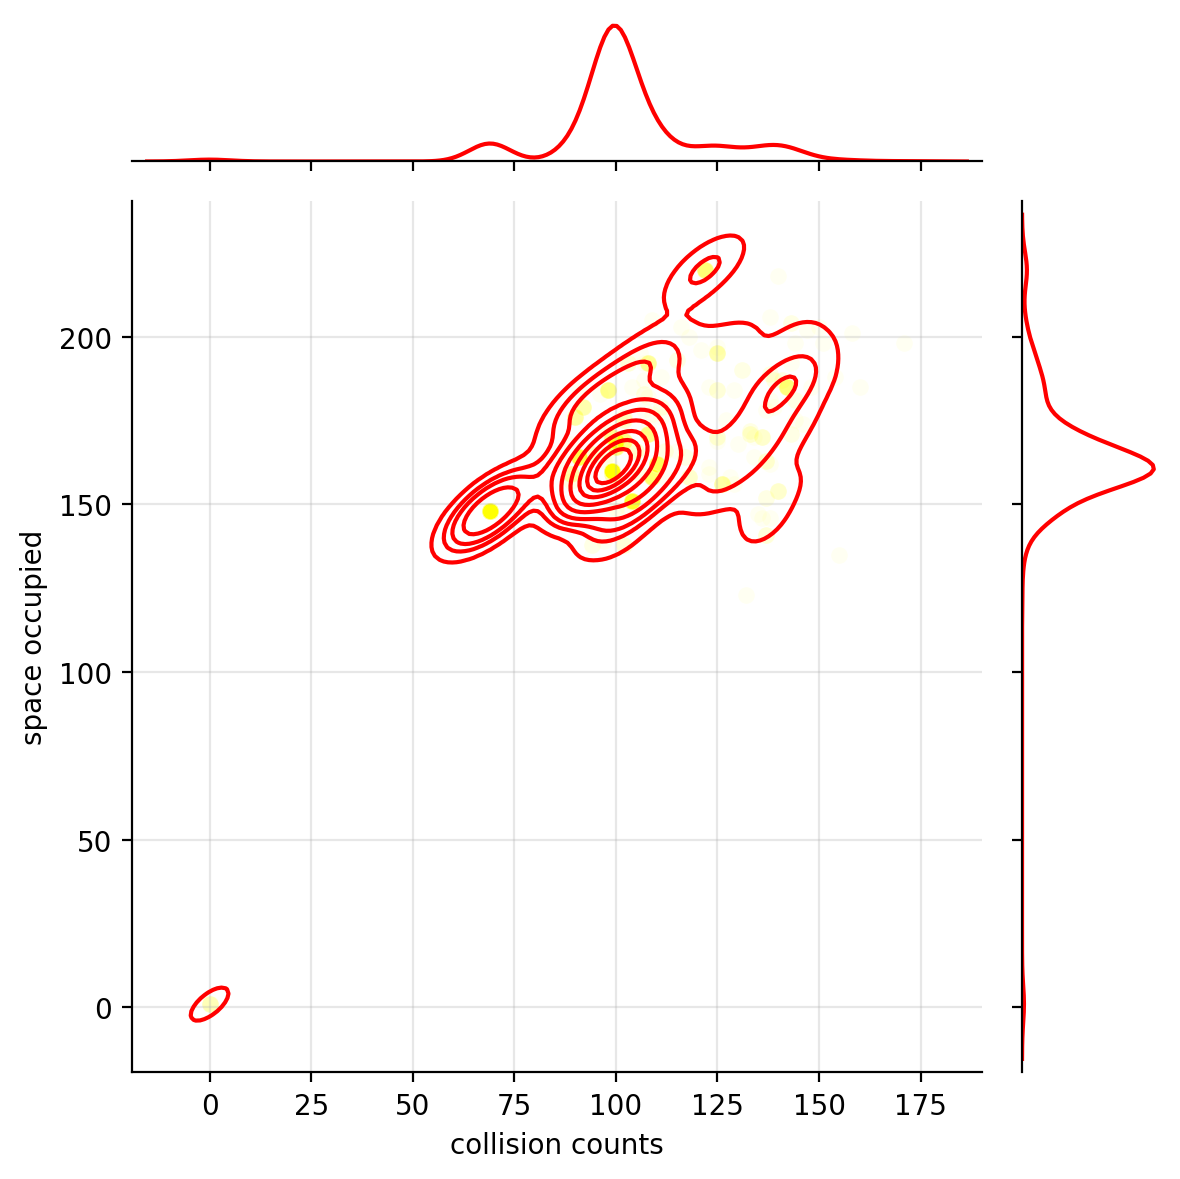

In [ ]:

plt.figure(figsize=(10,10))
sns.jointplot(scores_dataframe, x="wall collision total", y="space_occupied", kind="kde", color="red")
sns.scatterplot(scores_dataframe, x="wall collision total", y="space_occupied", alpha =0.05, color="yellow")
plt.ylabel("space occupied")
plt.xlabel("collision counts")
# plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("./kde_scatterplot.png", transparent= True)
plt.show()

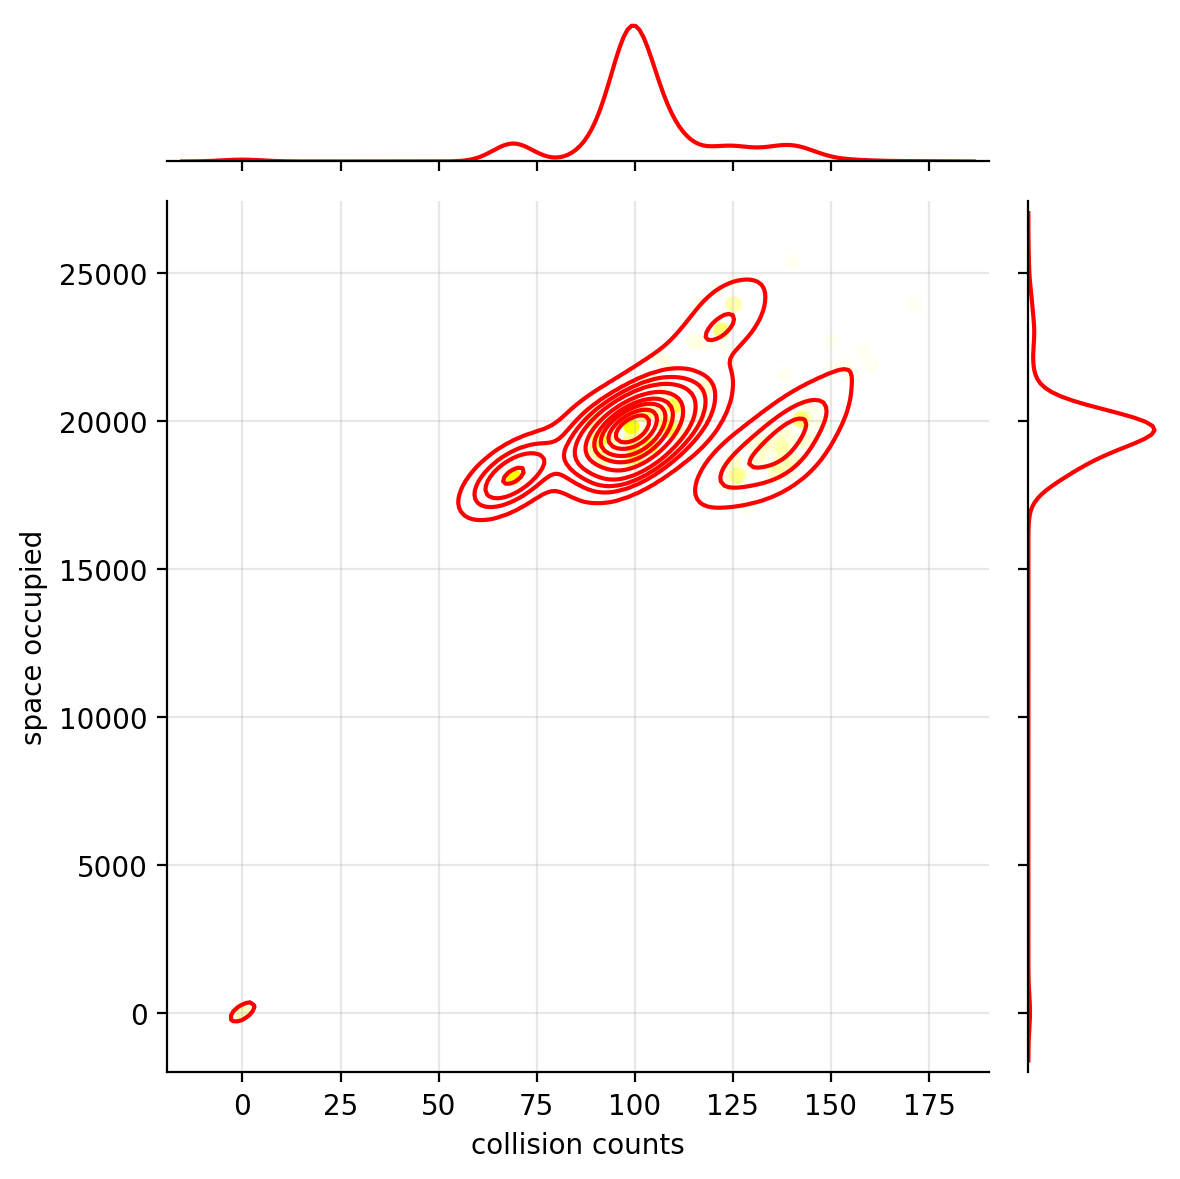

In [ ]:
# plt.figure(figsize=(10,10))
sns.jointplot(scores_dataframe, x="wall collision total", y="duration", kind="kde", color="red")
sns.scatterplot(scores_dataframe, x="wall collision total", y="duration", alpha =0.05, color="yellow")
plt.ylabel("space occupied")
plt.xlabel("collision counts")
# plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("./kde_scatterplot_2.png", transparent= True)
plt.show()

In [ ]:
chart = mo.ui.altair_chart(alt.Chart(scores_dataframe).mark_point().encode(
    x='wall collision total',
    y='duration',
    color='space_occupied'
))

In [ ]:
mo.vstack([chart, mo.ui.table(chart.value)])

In [ ]:
subset_dataframe = scores_dataframe[scores_dataframe["wall collision total"]<5]
fig = plt.figure(figsize=(6,6))
ax = Axes3D(fig, auto_add_to_figure=False)
fig.add_axes(ax)
sc = ax.scatter(subset_dataframe["wall collision total"], subset_dataframe["duration"], subset_dataframe["space_occupied"], s=40, marker='o', alpha=1)
ax.set_xlabel('wall collisions')
ax.set_ylabel('duration')
ax.set_zlabel('space occupied')
plt.show()

In [ ]:
varying_params = np.array([
    "CALL_RATE_FAST",
    "CALL_DIRECTIONALITY",
    "EMITTED_SPL",
    "HEARING_THRESHOLD",
    "BAT_RADIAL_RESOLUTION",
    "BAT_ANGULAR_RESOLUTION",
    "BAT_FRONTAL_RANGE",
    "CONSISTENCY_TIME_DELAY_CAP",
    "MEMORY_WINDOW_FOR_CONSISTENCY",
])
labels = np.array(['fast call rate (Hz)', 'call directionality', 'emitted spl', 'hearing threshold (dB)', 'radial resolution', 'angular resolution', 'frontal range (degrees)', 'consistency time delay cap', 'memory window'])
number_of_params = len(varying_params)

In [ ]:

plt.figure(figsize=(25,20))
number_of_subfigs = int(np.ceil(number_of_params/3))
bat_speeds = [1,3,5]

for i, param in enumerate(varying_params):
    df_low_collisions_given_bat_speed = scores_dataframe[scores_dataframe["wall collision total"]<5]
    plt.subplot(3,number_of_subfigs,i+1)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    sns.countplot(df_low_collisions_given_bat_speed, x=param, stat="percent", palette="viridis")
    plt.ylim(0,82)
    plt.xlabel("bat speed")
    # plt.legend(title="balls")
    plt.legend(title= labels[list(varying_params).index(param)])

plt.savefig("param_counts_10.svg", transparent= True)
plt.show()
plt.clf()

In [ ]:
plt.figure(figsize=(25,20))
for i_d, param_d in enumerate(varying_params):
    df_low_durations_given_bat_speed = scores_dataframe[(scores_dataframe["duration"]<25000) & (scores_dataframe["wall collision total"]<5) & (scores_dataframe["space_occupied"]>100)]
    plt.subplot(3,number_of_subfigs,i_d+1)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    sns.countplot(df_low_durations_given_bat_speed, x=param_d, stat="percent", palette="viridis")
    plt.ylim(0,82)
    plt.xlabel(labels[list(varying_params).index(param_d)])
    # plt.legend(title="balls")
    # plt.legend(title= labels[list(varying_params).index(param_d)])

plt.savefig("param_counts_10.svg", transparent= True)
plt.show()
plt.clf()

In [ ]:
plt.hist(df_low_durations_given_bat_speed["space_occupied"])
plt.show()
plt.hist(df_low_durations_given_bat_speed["wall collision total"])

Checking score saturation across seeds

In [ ]:
fig1 = plt.figure(figsize=(6,6))
ax2 = Axes3D(fig1, auto_add_to_figure=False)
fig1.add_axes(ax2)
sc1 = ax2.scatter(scores_dataframe["seed"], scores_dataframe["duration"], scores_dataframe["space_occupied"], s=40, marker='o', alpha=1)
ax2.set_xlabel('seed')
ax2.set_ylabel('duration')
ax2.set_zlabel('space occupied')
plt.show()

In [ ]:
sns.violinplot(x=scores_dataframe["seed"], y=scores_dataframe["wall collision total"], alpha=1)

In [ ]:
import plotly.express as px


mo._runtime.context.get_context().marimo_config["runtime"][
    "output_max_bytes"
] = 16_000_000

In [ ]:
def find_pareto_front(df, obj_cols):
    """
    Find Pareto optimal points in a DataFrame.

    Parameters:
    - df: DataFrame with columns in obj_cols
    - obj_cols: list of column names: ['wall collision total', 'space_occupied', 'duration']

    Returns:
    - Boolean mask: True for Pareto optimal points
    """
    # Extract objective values
    data = df[obj_cols].values  # shape: (n, 3)
    n = len(data)

    # Initialize mask: assume all are non-dominated initially
    is_pareto = [True] * n

    # Compare each point against every other point
    for i in range(n):
        for j in range(n):
            if i == j:
                continue
            # Check if point j dominates point i
            # We want: j has better or equal in all, and strictly better in at least one
            # But note: we want to minimize collision and duration, maximize space
            # So we reverse the logic for space_occupied (maximize)
            if (data[j, 0] <= data[i, 0] and  # j has ≤ collisions
                data[j, 1] >= data[i, 1] and  # j has ≥ space
                data[j, 2] <= data[i, 2] and  # j has ≤ duration
                (data[j, 0] < data[i, 0] or
                 data[j, 1] > data[i, 1] or
                 data[j, 2] < data[i, 2])):  # at least one strict improvement
                is_pareto[i] = False
                break  # i is dominated, no need to check further
    return np.array(is_pareto)

In [ ]:

import plotly.graph_objects as go

from scipy.spatial import ConvexHull


def plot_interactive_pareto(summary_df, output_file, optimized_params):
    """
    Interactive 3D Pareto plot with highlighted Pareto optimal points and surface.

    Objectives:
    - Minimize wall collision total
    - Maximize space_occupied
    - Minimize duration
    """
    # Define objective columns
    obj_cols = ["wall collision total", "space_occupied", "duration"]

    # Ensure all columns exist
    if not all(col in summary_df.columns for col in obj_cols):
        raise ValueError(f"Missing required columns: {obj_cols}")

    # Step 1: Find Pareto optimal points
    is_pareto = find_pareto_front(summary_df, obj_cols)
    pareto_df = summary_df[is_pareto].copy()
    non_pareto_df = summary_df[~is_pareto].copy()

    # Step 2: Prepare hover data
    hover_data = {"job id": True}
    hover_data.update({param: True for param in optimized_params})

    # Step 3: Create base scatter plot (non-Pareto points)
    fig = px.scatter_3d(
        non_pareto_df,
        x="wall collision total",
        y="space_occupied",
        z="duration",
        hover_data=hover_data,
        opacity=0.1,
        size_max = 0.1,
        color_discrete_sequence=["lightgray"],
    )

    # Step 4: Add Pareto points (highlighted)
    pareto_scatter = px.scatter_3d(
        pareto_df,
        x="wall collision total",
        y="space_occupied",
        z="duration",
        hover_data=hover_data,
        opacity=1,
        size_max = 0.1,
        color_discrete_sequence=["red"],
    )

    # Add Pareto points to figure
    for trace in pareto_scatter.data:
        fig.add_trace(trace)
    fig.update_traces(marker=dict(size=1))
    # Step 5: Fit a surface (Convex Hull approximation of Pareto front)
    # Only if we have enough points
    if len(pareto_df) >= 4:
        points = pareto_df[obj_cols].values  # (n, 3)
        try:
            hull = ConvexHull(points)
            # Create a mesh for the convex hull surface
            for simplex in hull.simplices:
                # Each simplex is a triangle (3 points)
                p1, p2, p3 = points[simplex]
                # Add triangle to the figure
                fig.add_trace(go.Mesh3d(
                    x=[p1[0], p2[0], p3[0]],
                    y=[p1[1], p2[1], p3[1]],
                    z=[p1[2], p2[2], p3[2]],
                    color='rgba(255, 165, 0, 0.2)',
                    opacity=0.5,
                    showlegend=True
                ))
        except Exception as e:
            print("Could not compute convex hull:", e)

    # Step 6: Update layout
    fig.update_layout(
        width=900,
        height=800,
        title="Pareto Front: Pareto Optimal Solutions (Red) with Surface Approximation",
        scene=dict(
            xaxis_title="Wall Collisions (counts)",
            yaxis_title="Space Occupied (counts)",
            zaxis_title="Duration (s)",
        ),
        legend_title_text="Legend",
        margin=dict(l=0, r=0, b=0, t=50)
    )

    # Save and show
    fig.write_html(output_file)
    fig.show()

    return pareto_df

In [ ]:
pareto_df = plot_interactive_pareto(scores_dataframe, "./scatter_plot.html", varying_params)

In [ ]:


plt.figure(figsize=(25,20))
for i_d, param_d in enumerate(varying_params):
    df_low_durations_given_bat_speed = scores_dataframe[(scores_dataframe["duration"]<25000) & (scores_dataframe["wall collision total"]<5) & (scores_dataframe["space_occupied"]>130)]
    plt.subplot(3,number_of_subfigs,i_d+1)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    sns.countplot(df_low_durations_given_bat_speed, x=param_d, stat="percent", palette="viridis")
    plt.ylim(0,82)
    plt.xlabel(labels[list(varying_params).index(param_d)])
    # plt.legend(title="balls")
    # plt.legend(title= labels[list(varying_params).index(param_d)])

plt.savefig("param_counts_10.svg", transparent= True)
plt.show()
plt.clf()